# Proyecto Data Science – Parte I
**Alumno:** Massironi  
**Dataset:** Marketing Campaign Dataset (`Defaultoutput.xlsx`)  
**Fecha:** Junio 2026

---
## Abstract

El presente proyecto analiza un dataset de campañas de marketing que contiene información demográfica, económica y de comportamiento de consumo de 2.240 clientes, con el objetivo de identificar los factores asociados al éxito de las acciones comerciales. El conjunto de datos incluye variables como año de nacimiento, nivel educativo, estado civil, ingresos anuales, recencia de la última compra, gasto desagregado en seis categorías de productos (vinos, frutas, carnes, pescados, golosinas y artículos dorados), canales de compra utilizados (web, catálogo y tienda física) y la variable objetivo `Response`, que indica si el cliente aceptó la última campaña de marketing ejecutada por la empresa.

El análisis se desarrolla mediante técnicas de Análisis Exploratorio de Datos (EDA) utilizando Python y las librerías pandas, Matplotlib y Seaborn. A través de estadísticas descriptivas y representaciones gráficas se busca comprender la distribución de las variables, detectar patrones de comportamiento, identificar posibles valores atípicos y explorar relaciones entre las características de los clientes y la aceptación de campañas de marketing.

La pregunta principal que guía este estudio es: **¿Qué características de los clientes están asociadas con una mayor probabilidad de responder positivamente a una campaña de marketing?** Para responderla se plantean cuatro hipótesis de trabajo: (H1) los clientes con mayores ingresos presentan una mayor tasa de respuesta positiva; (H2) los clientes que gastan más en productos tienen más probabilidades de aceptar campañas; (H3) los clientes con mayor cantidad de compras online responden más favorablemente; y (H4) la edad del cliente influye en su predisposición a aceptar campañas.

Además, se realizará una revisión de la calidad de los datos mediante la identificación y cuantificación de valores faltantes, con el fin de evaluar su potencial impacto en los resultados del análisis. En etapas posteriores se definirá la estrategia de tratamiento más adecuada (eliminación o imputación). Las conclusiones preliminares obtenidas permitirán comprender mejor el perfil de los clientes con mayor predisposición a responder favorablemente, aportando información valiosa para la toma de decisiones comerciales y la optimización de futuras estrategias de segmentación en campañas de marketing.

---
## 1. Pregunta problema e hipótesis de interés

**Pregunta problema:**  
¿Qué características de los clientes están asociadas con una mayor probabilidad de responder positivamente a una campaña de marketing?

**Hipótesis:**

- **H1:** Los clientes con mayores ingresos (`Income`) presentan una mayor tasa de respuesta positiva (`Response`).
- **H2:** Los clientes que gastan más en productos (`MntWines`, `MntMeatProducts`, `MntFishProducts`, etc.) tienen más probabilidades de aceptar campañas.
- **H3:** Los clientes con mayor cantidad de compras online (`NumWebPurchases`) responden más favorablemente a las campañas.
- **H4:** La edad del cliente (derivada de `Year_Birth`) influye en la aceptación de campañas.

---
## 2. Importación de librerías y carga de datos

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')

# Busca el Excel en la carpeta actual; si no lo encuentra, lo busca en Downloads
_nombre = 'Defaultoutput.xlsx'
_ruta = _nombre if os.path.exists(_nombre) else os.path.join(os.path.expanduser('~'), 'Downloads', _nombre)
print('Cargando archivo desde:', os.path.abspath(_ruta))

df = pd.read_excel(_ruta)

# Variables derivadas
df['Age'] = 2024 - df['Year_Birth']
df['TotalSpend'] = (df['MntWines'] + df['MntFruits'] + df['MntMeatProducts'] +
                    df['MntFishProducts'] + df['MntSweetProducts'] + df['MntGoldProds'])

# Convertir Response a string (funciona con bool, int o str)
df['Response_str'] = df['Response'].astype(bool).map({True: 'Si', False: 'No'})

print('Dimensiones del dataset:', df.shape)
df.head()

Cargando archivo desde: C:\Users\lujan\Downloads\Defaultoutput.xlsx


Dimensiones del dataset: (2240, 37)


,Unnamed: 0,index,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,...,Complain,Z_CostContact,Z_Revenue,Response,MostExpensive,Marital_Status_key,Education_key,Age,TotalSpend,Response_str
0,0,0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,...,False,3,11,True,Wines,0,1,67,1617,Si
1,1,1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,...,False,3,11,False,Wines,0,1,70,27,No
2,2,2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,...,False,3,11,False,Wines,2,1,59,776,No
3,3,3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,...,False,3,11,False,MeatProducts,2,1,40,53,No
4,4,4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,...,False,3,11,False,Wines,1,0,43,422,No


---
## 3. Identificación de valores perdidos

In [2]:
df.isnull().sum().sort_values(ascending=False)

Income                 24
index                   0
ID                      0
Year_Birth              0
Unnamed: 0              0
Education               0
Marital_Status          0
Kidhome                 0
Teenhome                0
Dt_Customer             0
Recency                 0
MntWines                0
MntFruits               0
MntMeatProducts         0
MntFishProducts         0
MntSweetProducts        0
MntGoldProds            0
NumDealsPurchases       0
NumWebPurchases         0
NumCatalogPurchases     0
NumStorePurchases       0
NumWebVisitsMonth       0
AcceptedCmp3            0
AcceptedCmp4            0
AcceptedCmp5            0
AcceptedCmp1            0
AcceptedCmp2            0
Complain                0
Z_CostContact           0
Z_Revenue               0
Response                0
MostExpensive           0
Marital_Status_key      0
Education_key           0
Age                     0
TotalSpend              0
Response_str            0
dtype: int64

**Interpretación:**  
Se identificaron **24 valores faltantes** en la variable `Income`, que representan el 1,07% del total de registros. El resto de las variables del dataset están completas. Estos valores ausentes serán considerados en futuras etapas de limpieza: dado su bajo porcentaje, se podría optar por eliminarlos (`dropna()`) o imputarlos con la mediana (`fillna()`) sin afectar significativamente el análisis.

---
## 4. Resumen numérico

In [3]:
df[['Income', 'Age', 'MntWines', 'MntMeatProducts',
    'NumWebPurchases', 'NumStorePurchases', 'Recency', 'TotalSpend']].describe().round(2)

,Income,Age,MntWines,MntMeatProducts,NumWebPurchases,NumStorePurchases,Recency,TotalSpend
count,2216.00,2240.00,2240.00,2240.00,2240.00,2240.00,2240.00,2240.00
mean,52247.25,55.19,303.94,166.95,4.08,5.79,49.11,605.80
std,25173.08,11.98,336.60,225.72,2.78,3.25,28.96,602.25
min,1730.00,28.00,0.00,0.00,0.00,0.00,0.00,5.00
25%,35303.00,47.00,23.75,16.00,2.00,3.00,24.00,68.75
50%,51381.50,54.00,173.50,67.00,4.00,5.00,49.00,396.00
75%,68522.00,65.00,504.25,232.00,6.00,8.00,74.00,1045.50
max,666666.00,131.00,1493.00,1725.00,27.00,13.00,99.00,2525.00


In [4]:
# Comparación de promedios según respuesta a campaña
df.groupby('Response_str')[['Income', 'Age', 'TotalSpend', 'NumWebPurchases', 'Recency']].mean().round(2)

,Income,Age,TotalSpend,NumWebPurchases,Recency
Response_str,,,,,
No,50839.13,55.30,538.93,3.91,51.51
Si,60209.68,54.58,987.39,5.07,35.38


**Interpretación:**  
Las estadísticas descriptivas muestran que el ingreso promedio es de USD 52.247, con alta dispersión. Al comparar por grupos de respuesta, los clientes que aceptaron la campaña tienen ingresos promedio superiores (~USD 60.210 vs. ~USD 50.839), mayor gasto total (~USD 987 vs. ~USD 539) y más compras web. Esto vincula con **H1**, **H2** y **H3**. La edad promedio es similar entre ambos grupos, lo que debilita **H4**.

---
## 5. Visualizaciones

### Gráfico 1 – Distribución de ingresos (univariado — histograma)

**Vinculación con H1:** antes de analizar la relación entre ingresos y respuesta, exploramos cómo se distribuye la variable `Income` en el dataset.

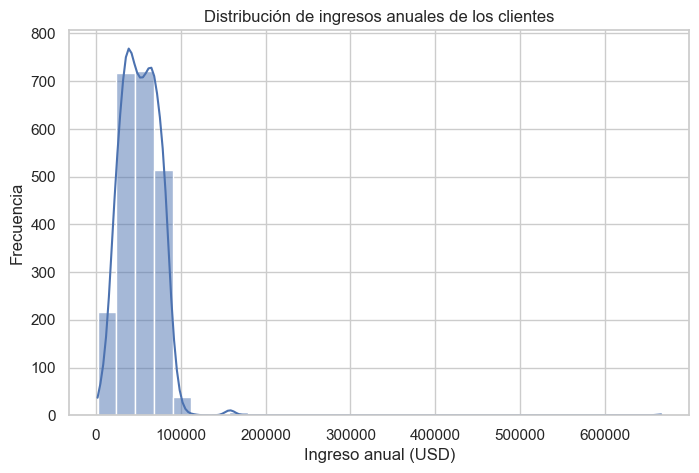

In [5]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x='Income', bins=30, kde=True)
plt.title('Distribución de ingresos anuales de los clientes')
plt.xlabel('Ingreso anual (USD)')
plt.ylabel('Frecuencia')
plt.show()

**Interpretación:**  
La distribución de ingresos presenta una concentración principal entre USD 20.000 y USD 80.000, con una cola derecha prolongada que indica la presencia de valores atípicos en ingresos muy elevados. La asimetría positiva sugiere que la media es superior a la mediana. Comprender esta distribución es el punto de partida para evaluar si el ingreso discrimina la respuesta a campañas, tal como plantea **H1**.

### Gráfico 2 – Ingresos según respuesta a campañas (bivariado — boxplot)

**Vinculación con H1:** el boxplot permite comparar la distribución de `Income` entre quienes aceptaron y rechazaron la campaña.

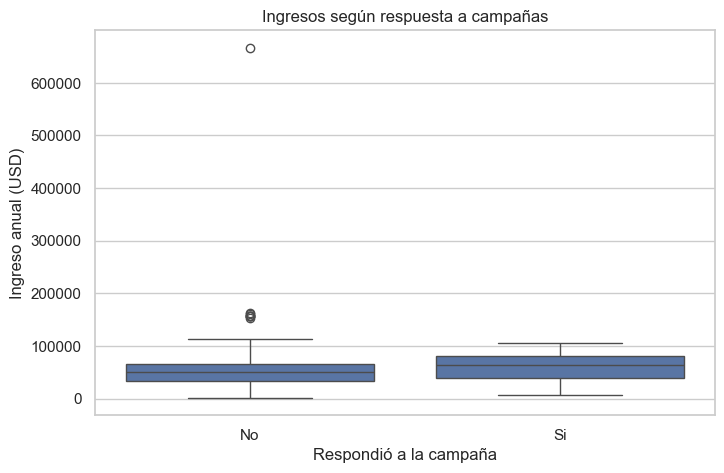

In [6]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='Response_str', y='Income', order=['No', 'Si'])
plt.title('Ingresos según respuesta a campañas')
plt.xlabel('Respondió a la campaña')
plt.ylabel('Ingreso anual (USD)')
plt.show()

**Interpretación:**  
Los clientes que respondieron positivamente ("Si") exhiben una mediana de ingresos claramente superior respecto a quienes no respondieron ("No"). El rango intercuartílico del grupo "Si" también se ubica en valores más altos. Esto confirma la evidencia a favor de **H1**: el nivel de ingresos es una variable diferenciadora entre quienes aceptan o rechazan las campañas.

### Gráfico 3 – Compras web por nivel educativo y respuesta a campaña (bivariado — barplot con hue)

**Vinculación con H3:** comparamos la cantidad promedio de compras web (`NumWebPurchases`) según nivel educativo y respuesta.

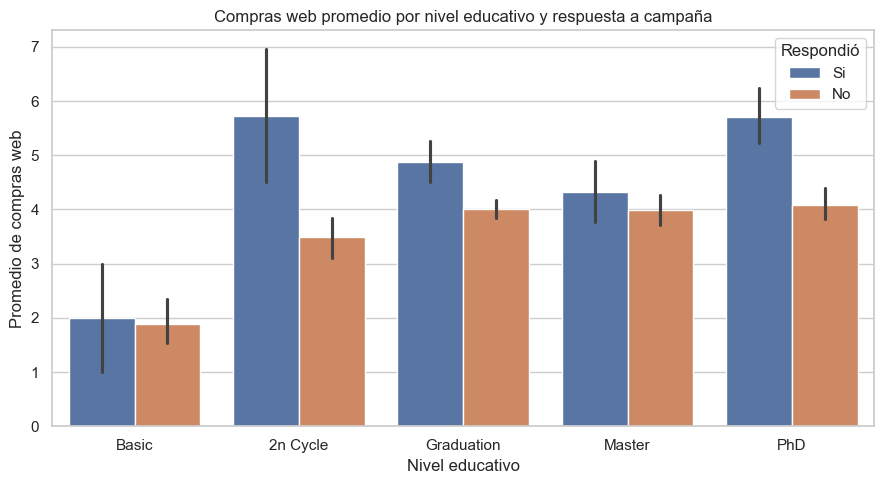

In [7]:
plt.figure(figsize=(9, 5))
sns.barplot(
    data=df,
    x='Education',
    y='NumWebPurchases',
    hue='Response_str',
    order=['Basic', '2n Cycle', 'Graduation', 'Master', 'PhD']
)
plt.title('Compras web promedio por nivel educativo y respuesta a campaña')
plt.xlabel('Nivel educativo')
plt.ylabel('Promedio de compras web')
plt.legend(title='Respondió')
plt.tight_layout()
plt.show()

**Interpretación:**  
En todos los niveles educativos, los clientes que aceptaron la campaña presentan un promedio de compras web mayor que quienes no respondieron. Esto aporta evidencia a favor de **H3**: una mayor actividad de compra online se asocia con mayor aceptación de campañas. Además, se observan diferencias entre niveles educativos, lo que sugiere oportunidades de segmentación.

### Gráfico 4 – Ingresos, gasto en vinos y compras web según respuesta (multivariable — scatterplot con hue y size)

**Vinculación con H1, H2 y H3:** este gráfico integra cuatro variables en un único plano para detectar patrones combinados.

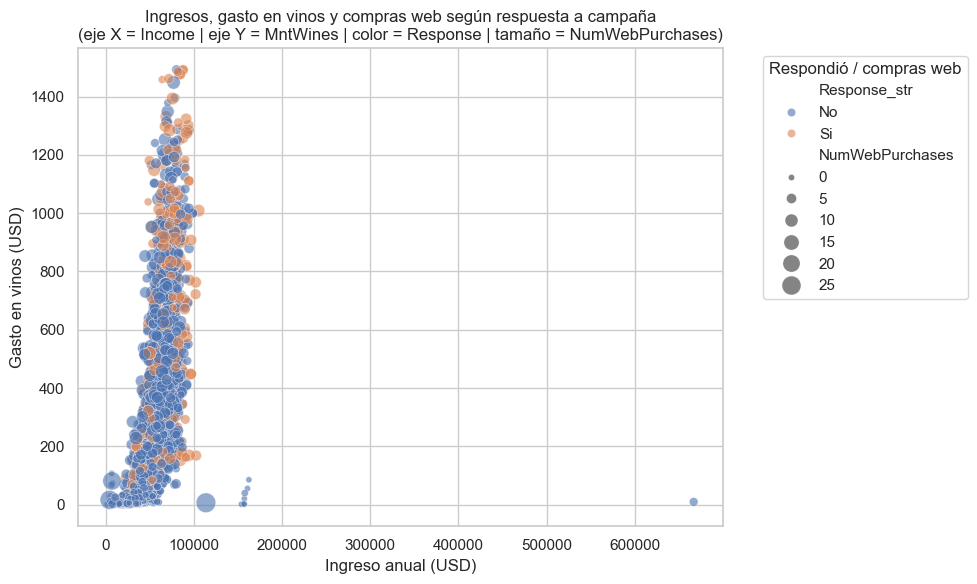

In [8]:
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df,
    x='Income',
    y='MntWines',
    hue='Response_str',
    size='NumWebPurchases',
    sizes=(20, 200),
    alpha=0.6,
    hue_order=['No', 'Si']
)
plt.title('Ingresos, gasto en vinos y compras web según respuesta a campaña\n'
          '(eje X = Income | eje Y = MntWines | color = Response | tamaño = NumWebPurchases)')
plt.xlabel('Ingreso anual (USD)')
plt.ylabel('Gasto en vinos (USD)')
plt.legend(title='Respondió / compras web', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

**Diagnóstico — vinculación con H1, H2 y H3:**  
Este gráfico usa cuatro variables simultáneamente y permite observar:

- **H1 (Income):** Los puntos del grupo "Si" se concentran en el cuadrante de mayores ingresos, reforzando H1.
- **H2 (MntWines como proxy de gasto):** Los clientes con mayor gasto en vinos tienden a responder positivamente, aportando evidencia a H2.
- **H3 (NumWebPurchases):** Los puntos de mayor tamaño (más compras web) aparecen con mayor frecuencia en el grupo "Si", respaldando H3.
- Existe una relación positiva entre ingresos y gasto en vinos: a mayor ingreso, mayor consumo. Los clientes con respuesta positiva se concentran en ese segmento de alto ingreso y alto consumo.

---
## 6. Conclusiones preliminares

El análisis exploratorio permite evaluar las hipótesis planteadas:

- **H1 — Ingresos ✅ Con evidencia:** Los clientes que aceptaron la campaña tienen ingresos promedio ~USD 9.370 más altos. El boxplot y el resumen numérico lo confirman.
- **H2 — Gasto en productos ✅ Con evidencia:** El gasto total promedio es casi el doble en el grupo que respondió positivamente (~USD 987 vs. ~USD 539). El scatterplot lo visualiza para vinos.
- **H3 — Compras online ✅ Con evidencia:** Más compras web se asocian con mayor aceptación, tanto en el barplot por educación como en el scatterplot multivariable.
- **H4 — Edad ⚠️ Sin evidencia clara:** La edad promedio es similar en ambos grupos (~55 años). La edad no aparece como variable diferenciadora en esta primera exploración.

En síntesis, el perfil del cliente con mayor probabilidad de responder positivamente a campañas de marketing se caracteriza por altos ingresos, elevado gasto en productos y alta frecuencia de compras online. Estos hallazgos orientan la segmentación para futuras campañas y sientan las bases para modelos predictivos en etapas posteriores del proyecto.